# Лабораторная работа 2
## Знакомство с инструментами сбора и подготовки данных

**Датасет:** объявления о продаже квартир (`RealEstate` / `train.csv`).

**Цель работы:** загрузить таблицу, найти и устранить пропуски и выбросы, создать новые признаки, закодировать категории и привести числовые признаки к единому масштабу.

Используются библиотеки из методических материалов: **pandas**, **matplotlib**, **scikit-learn**. Для тепловых карт дополнительно — **seaborn**.


## 1. Импорт датасета

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

df = pd.read_csv("data/train.csv")
print("Размер таблицы:", df.shape)
df.head()

Размер таблицы: (10000, 20)


,Id,DistrictId,Rooms,Square,LifeSquare,KitchenSquare,Floor,HouseFloor,HouseYear,Ecology_1,Ecology_2,Ecology_3,Social_1,Social_2,Social_3,Healthcare_1,Helthcare_2,Shops_1,Shops_2,Price
0,11809,27,3.0,115.027311,NaN,10.0,4,10.0,2014,0.075424,B,B,11,3097,0,NaN,0,0,B,305018.871089
1,3013,22,1.0,39.832524,23.169223,8.0,7,8.0,1966,0.118537,B,B,30,6207,1,1183.0,1,0,B,177734.553407
2,8215,1,3.0,78.342215,47.671972,10.0,2,17.0,1988,0.025609,B,B,33,5261,0,240.0,3,1,B,282078.720850
3,2352,1,1.0,40.409907,NaN,1.0,10,22.0,1977,0.007122,B,B,1,264,0,NaN,0,1,B,168106.007630
4,13866,94,2.0,64.285067,38.562517,9.0,16,16.0,1972,0.282798,B,B,33,8667,2,NaN,0,6,B,343995.102962


In [2]:
df.info()
print()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             10000 non-null  int64  
 1   DistrictId     10000 non-null  int64  
 2   Rooms          10000 non-null  float64
 3   Square         10000 non-null  float64
 4   LifeSquare     7887 non-null   float64
 5   KitchenSquare  10000 non-null  float64
 6   Floor          10000 non-null  int64  
 7   HouseFloor     10000 non-null  float64
 8   HouseYear      10000 non-null  int64  
 9   Ecology_1      10000 non-null  float64
 10  Ecology_2      10000 non-null  str    
 11  Ecology_3      10000 non-null  str    
 12  Social_1       10000 non-null  int64  
 13  Social_2       10000 non-null  int64  
 14  Social_3       10000 non-null  int64  
 15  Healthcare_1   5202 non-null   float64
 16  Helthcare_2    10000 non-null  int64  
 17  Shops_1        10000 non-null  int64  
 18  Shops_2        100

,count,mean,std,min,25%,50%,75%,max
Id,10000.0,8383.407700,4859.019020,0.000000,4169.500000,8394.500000,12592.500000,1.679800e+04
DistrictId,10000.0,50.400800,43.587592,0.000000,20.000000,36.000000,75.000000,2.090000e+02
Rooms,10000.0,1.890500,0.839512,0.000000,1.000000,2.000000,2.000000,1.900000e+01
Square,10000.0,56.315775,21.058732,1.136859,41.774881,52.513310,65.900625,6.410652e+02
LifeSquare,7887.0,37.199645,86.241209,0.370619,22.769832,32.781260,45.128803,7.480592e+03
KitchenSquare,10000.0,6.273300,28.560917,0.000000,1.000000,6.000000,9.000000,2.014000e+03
Floor,10000.0,8.526700,5.241148,1.000000,4.000000,7.000000,12.000000,4.200000e+01
HouseFloor,10000.0,12.609400,6.775974,0.000000,9.000000,13.000000,17.000000,1.170000e+02
HouseYear,10000.0,3990.166300,200500.261427,1910.000000,1974.000000,1977.000000,2001.000000,2.005201e+07
Ecology_1,10000.0,0.118858,0.119025,0.000000,0.017647,0.075424,0.195781,5.218671e-01


Кратко о данных:
- 10 000 строк, 20 столбцов;
- числовые признаки квартиры: `Rooms`, `Square`, `LifeSquare`, `KitchenSquare`, `Floor`, `HouseFloor`, `HouseYear`, `Price`;
- экологические и социальные признаки района: `Ecology_*`, `Social_*`, `Healthcare_1`, `Helthcare_2`, `Shops_*`;
- категориальные признаки с метками `A`/`B`: `Ecology_2`, `Ecology_3`, `Shops_2`.


## 2. Пропуски и аномальные значения

Сначала смотрим пропуски статистикой и тепловой картой.


In [3]:
missing = pd.DataFrame({
    "пропусков": df.isna().sum(),
    "доля, %": (df.isna().mean() * 100).round(2),
})
missing[missing["пропусков"] > 0]

,пропусков,"доля, %"
LifeSquare,2113,21.13
Healthcare_1,4798,47.98


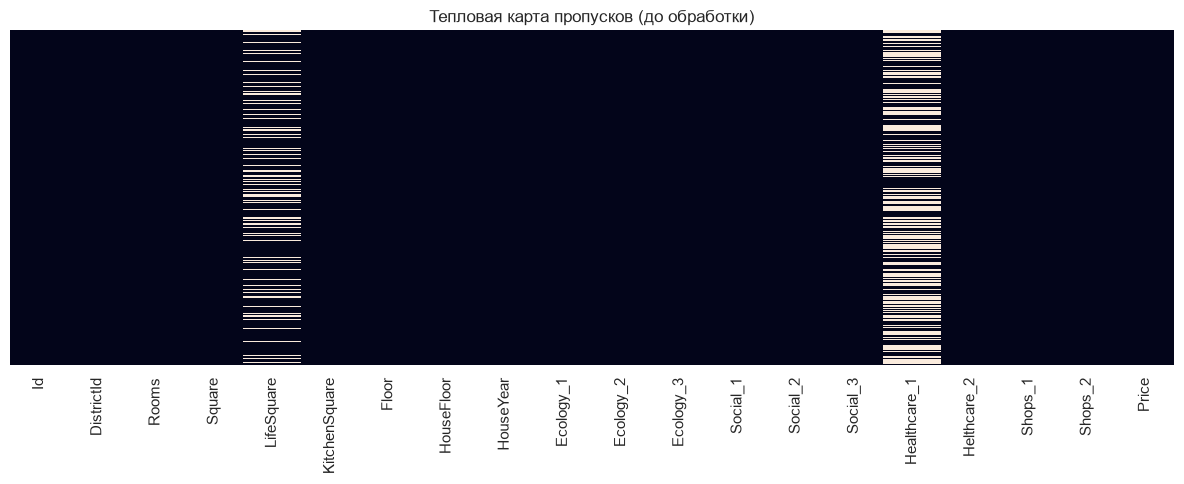

In [4]:
plt.figure(figsize=(12, 5))
sns.heatmap(df.isna(), cbar=False, yticklabels=False)
plt.title("Тепловая карта пропусков (до обработки)")
plt.tight_layout()
plt.show()

Пропуски есть в двух столбцах:
- `LifeSquare` — около 21%;
- `Healthcare_1` — около 48%.

По методичке признак удаляют, если пропусков больше 70%. Здесь порог не превышен, поэтому оба столбца оставляем и заполняем. Для числа — медианой (она устойчивее среднего к выбросам). Для `LifeSquare` дополнительно используем типичную долю жилой площади от общей, чтобы заполнение было реалистичнее.


### Поиск выбросов: статистики, гистограммы и BoxPlot

In [5]:
suspect = ["Rooms", "Square", "LifeSquare", "KitchenSquare",
           "Floor", "HouseFloor", "HouseYear", "Price"]
df[suspect].describe().T

,count,mean,std,min,25%,50%,75%,max
Rooms,10000.0,1.890500,0.839512,0.000000,1.000000,2.000000,2.000000,1.900000e+01
Square,10000.0,56.315775,21.058732,1.136859,41.774881,52.513310,65.900625,6.410652e+02
LifeSquare,7887.0,37.199645,86.241209,0.370619,22.769832,32.781260,45.128803,7.480592e+03
KitchenSquare,10000.0,6.273300,28.560917,0.000000,1.000000,6.000000,9.000000,2.014000e+03
Floor,10000.0,8.526700,5.241148,1.000000,4.000000,7.000000,12.000000,4.200000e+01
HouseFloor,10000.0,12.609400,6.775974,0.000000,9.000000,13.000000,17.000000,1.170000e+02
HouseYear,10000.0,3990.166300,200500.261427,1910.000000,1974.000000,1977.000000,2001.000000,2.005201e+07
Price,10000.0,214138.857399,92872.293865,59174.778028,153872.633942,192269.644879,249135.462171,6.332335e+05


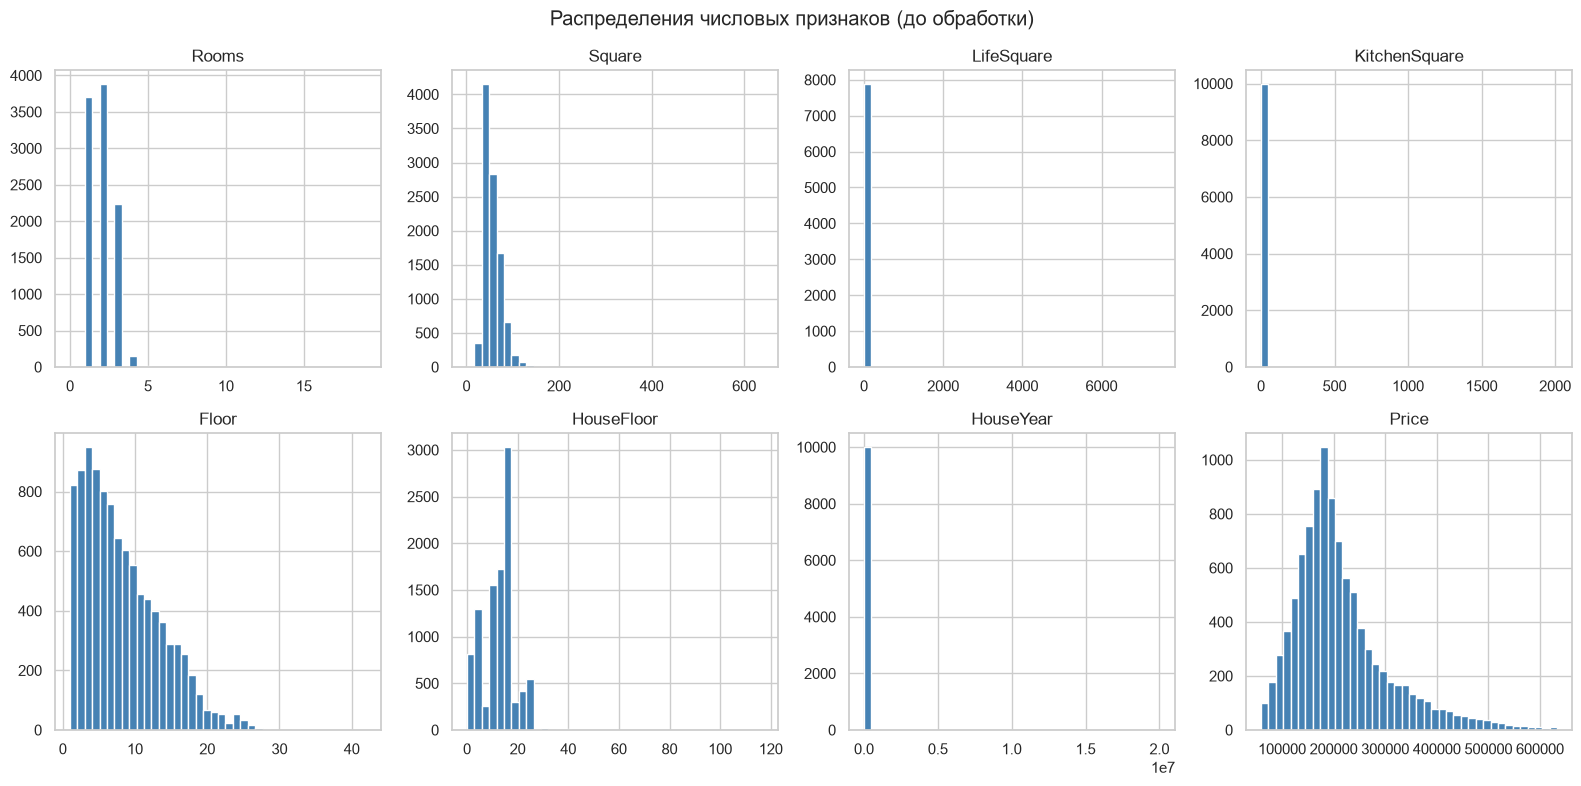

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.ravel(), suspect):
    ax.hist(df[col].dropna(), bins=40, color="steelblue", edgecolor="white")
    ax.set_title(col)
plt.suptitle("Распределения числовых признаков (до обработки)")
plt.tight_layout()
plt.show()

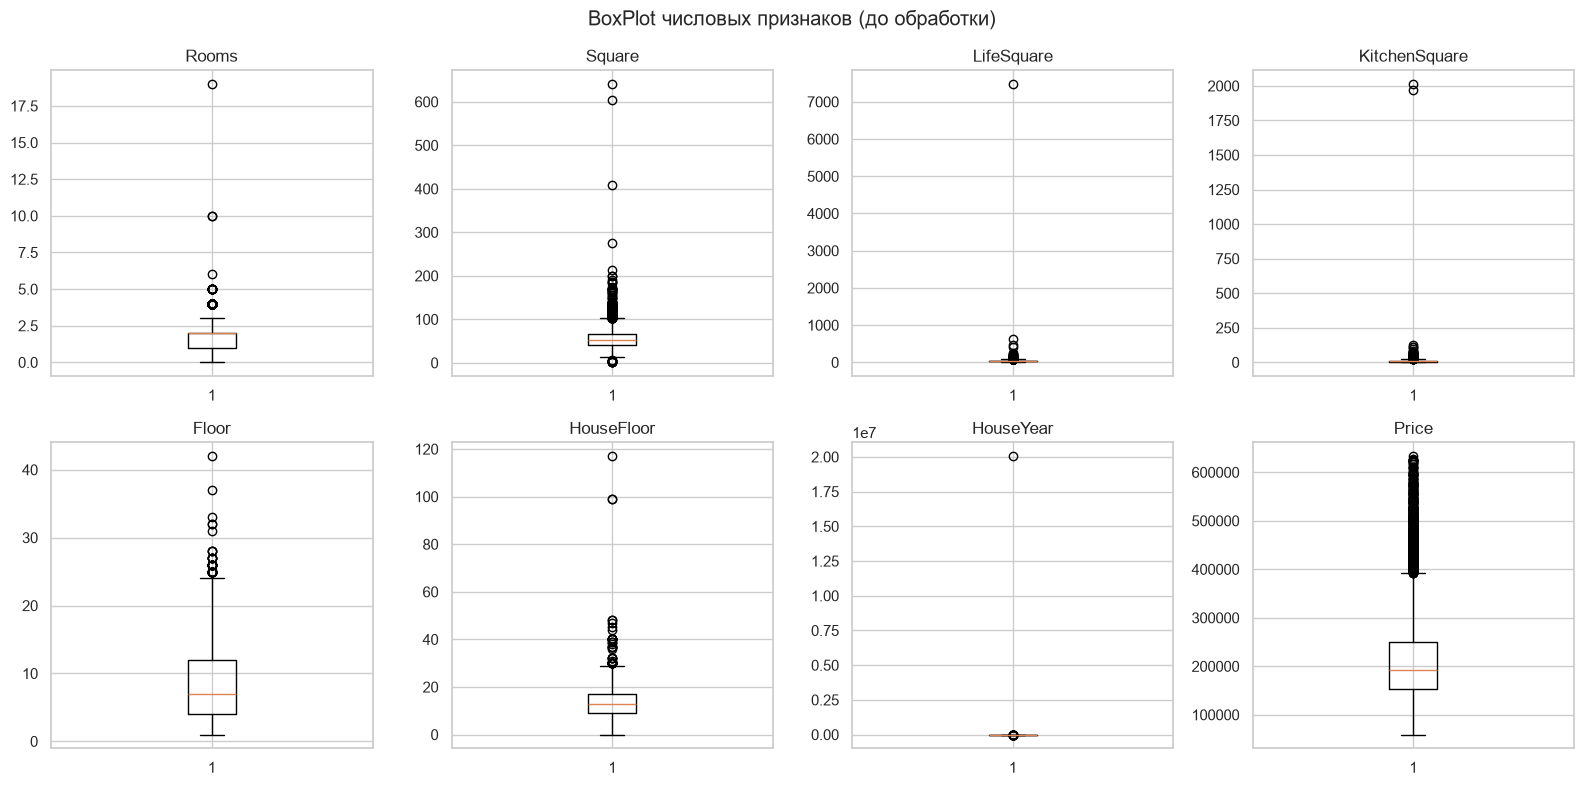

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.ravel(), suspect):
    ax.boxplot(df[col].dropna(), orientation='vertical')
    ax.set_title(col)
plt.suptitle("BoxPlot числовых признаков (до обработки)")
plt.tight_layout()
plt.show()

На графиках и в `describe()` видны явные ошибки ввода, а не просто «дорогие квартиры»:

- `HouseYear`: значения `20052011` и `4968` (год не может быть таким);
- `Rooms`: 0 комнат и 10–19 комнат при обычной площади;
- `Square` от 1 м² и до 641 м²;
- `LifeSquare` до 7480 м² (больше, чем вся квартира);
- `KitchenSquare` до 2014 (похоже, вписали год);
- `HouseFloor` = 0 и этаж квартиры выше этажности дома.

Для формального поиска выбросов используем **IQR** (интерквартильный размах) из разведочного анализа: выброс — значение за пределами 


In [8]:
def iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


print("Число точек за границами IQR:")
for col in suspect:
    low, high = iqr_bounds(df[col].dropna())
    n = ((df[col] < low) | (df[col] > high)).sum()
    print(f"  {col:15s}: {n:5d}   границы [{low:.2f}; {high:.2f}]")

Число точек за границами IQR:
  Rooms          :   172   границы [-0.50; 3.50]
  Square         :   242   границы [5.59; 102.09]
  LifeSquare     :   240   границы [-10.77; 78.67]
  KitchenSquare  :    47   границы [-11.00; 21.00]
  Floor          :    66   границы [-8.00; 24.00]
  HouseFloor     :    49   границы [-3.00; 29.00]
  HouseYear      :    38   границы [1933.50; 2041.50]
  Price          :   583   границы [10978.39; 392029.70]


### Устранение пропусков и выбросов

In [9]:
df_clean = df.copy()

# --- явные опечатки в годе постройки ---
df_clean.loc[df_clean["HouseYear"] == 20052011, "HouseYear"] = 2005
df_clean.loc[df_clean["HouseYear"] == 4968, "HouseYear"] = 1968
df_clean["HouseYear"] = df_clean["HouseYear"].clip(1910, 2020)

# --- комнаты: 0 заменяем на 1, экстремумы — на медиану ---
rooms_median = df_clean["Rooms"].median()
df_clean.loc[df_clean["Rooms"] < 1, "Rooms"] = 1
df_clean.loc[df_clean["Rooms"] > 6, "Rooms"] = rooms_median

# --- этажность: 0 этажей в доме и этаж выше дома ---
df_clean.loc[df_clean["HouseFloor"] <= 0, "HouseFloor"] = df_clean["Floor"]
too_high = df_clean["Floor"] > df_clean["HouseFloor"]
df_clean.loc[too_high, "HouseFloor"] = df_clean.loc[too_high, "Floor"]

# --- площадь кухни и жилая площадь не могут быть больше общей ---
df_clean.loc[df_clean["KitchenSquare"] > df_clean["Square"], "KitchenSquare"] = np.nan
df_clean.loc[df_clean["LifeSquare"] > df_clean["Square"], "LifeSquare"] = np.nan

# --- IQR-ограничение (winsorization): обрезаем хвосты, строки не удаляем ---
for col in ["Square", "LifeSquare", "KitchenSquare", "HouseFloor", "Price"]:
    low, high = iqr_bounds(df_clean[col].dropna())
    df_clean[col] = df_clean[col].clip(lower=max(low, 0), upper=high)

# --- пропуски ---
# Healthcare_1: медиана (количественный признак, доля пропусков < 70%)
df_clean["Healthcare_1"] = df_clean["Healthcare_1"].fillna(df_clean["Healthcare_1"].median())

# LifeSquare: медианная доля жилой площади от общей, иначе просто медиана
ratio = (df_clean["LifeSquare"] / df_clean["Square"]).median()
life_fill = df_clean["Square"] * ratio
df_clean["LifeSquare"] = df_clean["LifeSquare"].fillna(life_fill)
df_clean["LifeSquare"] = df_clean["LifeSquare"].fillna(df_clean["LifeSquare"].median())

# кухня после клипа могла стать NaN
df_clean["KitchenSquare"] = df_clean["KitchenSquare"].fillna(df_clean["KitchenSquare"].median())

print("Пропусков после обработки:", int(df_clean.isna().sum().sum()))
print("Размер таблицы:", df_clean.shape)
df_clean[suspect].describe().T

Пропусков после обработки: 0
Размер таблицы: (10000, 20)


,count,mean,std,min,25%,50%,75%,max
Rooms,10000.0,1.888000,0.812479,1.000000,1.000000,2.000000,2.000000,6.000000
Square,10000.0,55.738715,17.460980,5.586264,41.774881,52.513310,65.900625,102.089242
LifeSquare,10000.0,34.658864,13.869860,0.370619,23.852217,32.600139,43.561804,75.628059
KitchenSquare,10000.0,5.741700,4.005170,0.000000,1.000000,6.000000,9.000000,21.000000
Floor,10000.0,8.526700,5.241148,1.000000,4.000000,7.000000,12.000000,42.000000
HouseFloor,10000.0,13.386200,5.791097,1.000000,9.000000,14.000000,17.000000,29.000000
HouseYear,10000.0,1984.865700,18.411517,1910.000000,1974.000000,1977.000000,2001.000000,2020.000000
Price,10000.0,209726.267220,80618.194318,59174.778028,153872.633942,192269.644879,249135.462171,392029.704515


### Проверка: пропуски и выбросы после обработки

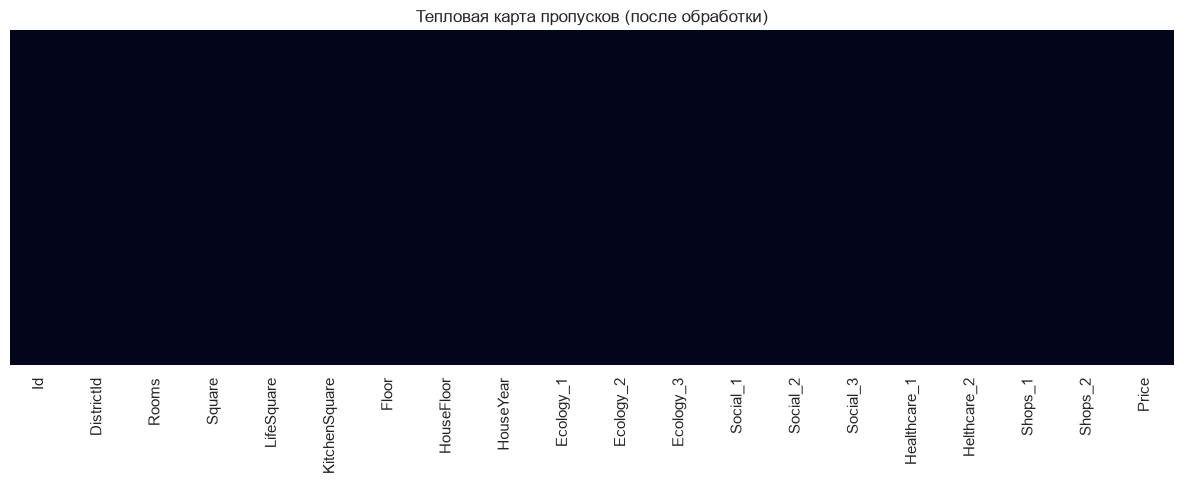

Пропуски по столбцам:
Id               0
DistrictId       0
Rooms            0
Square           0
LifeSquare       0
KitchenSquare    0
Floor            0
HouseFloor       0
HouseYear        0
Ecology_1        0
Ecology_2        0
Ecology_3        0
Social_1         0
Social_2         0
Social_3         0
Healthcare_1     0
Helthcare_2      0
Shops_1          0
Shops_2          0
Price            0
dtype: int64


In [10]:
plt.figure(figsize=(12, 5))
sns.heatmap(df_clean.isna(), cbar=False, yticklabels=False)
plt.title("Тепловая карта пропусков (после обработки)")
plt.tight_layout()
plt.show()

print("Пропуски по столбцам:")
print(df_clean.isna().sum())

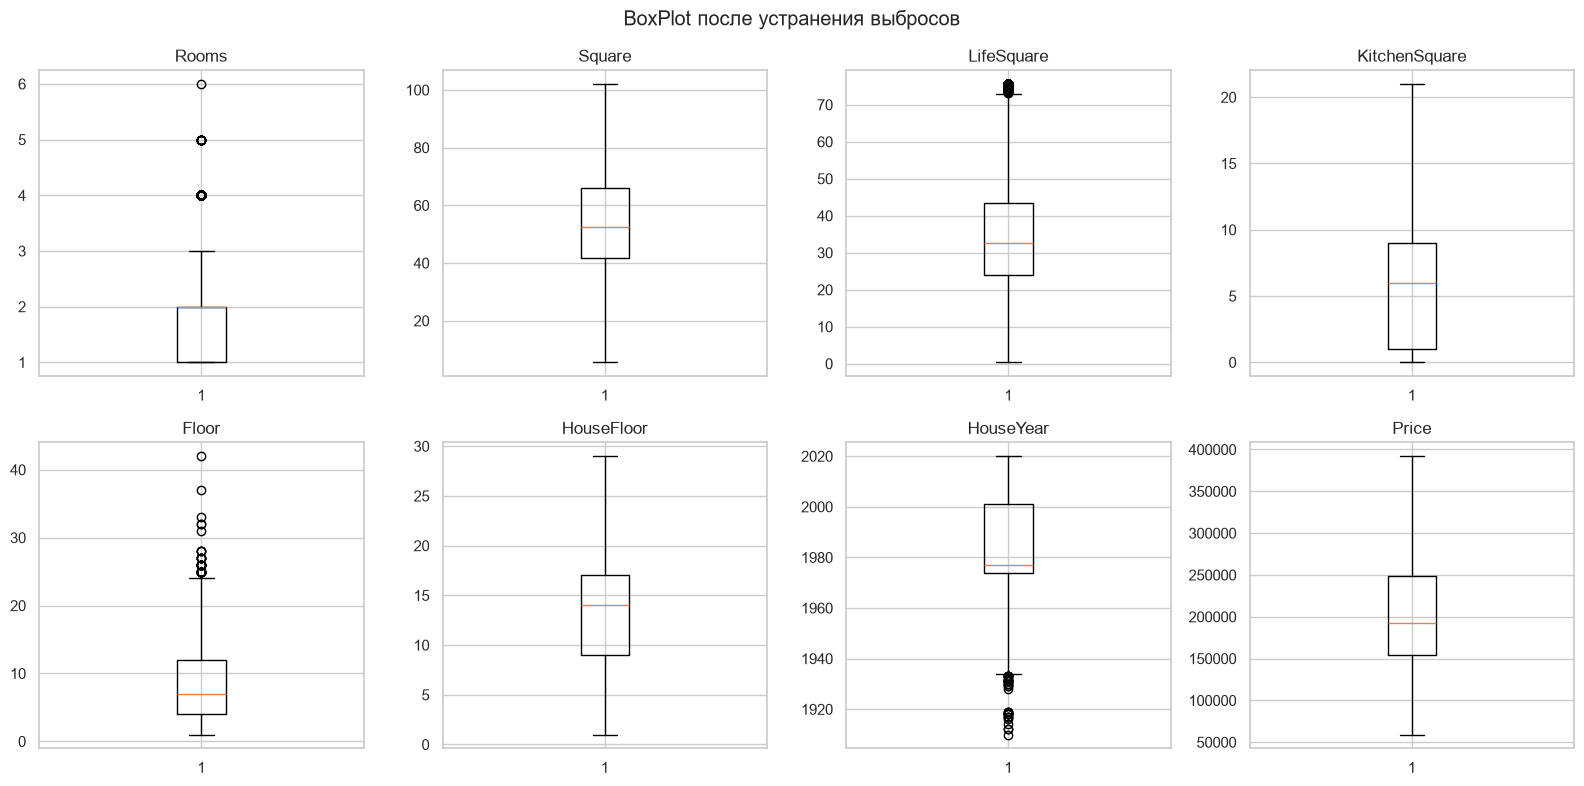

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.ravel(), suspect):
    ax.boxplot(df_clean[col].dropna(), orientation='vertical')
    ax.set_title(col)
plt.suptitle("BoxPlot после устранения выбросов")
plt.tight_layout()
plt.show()

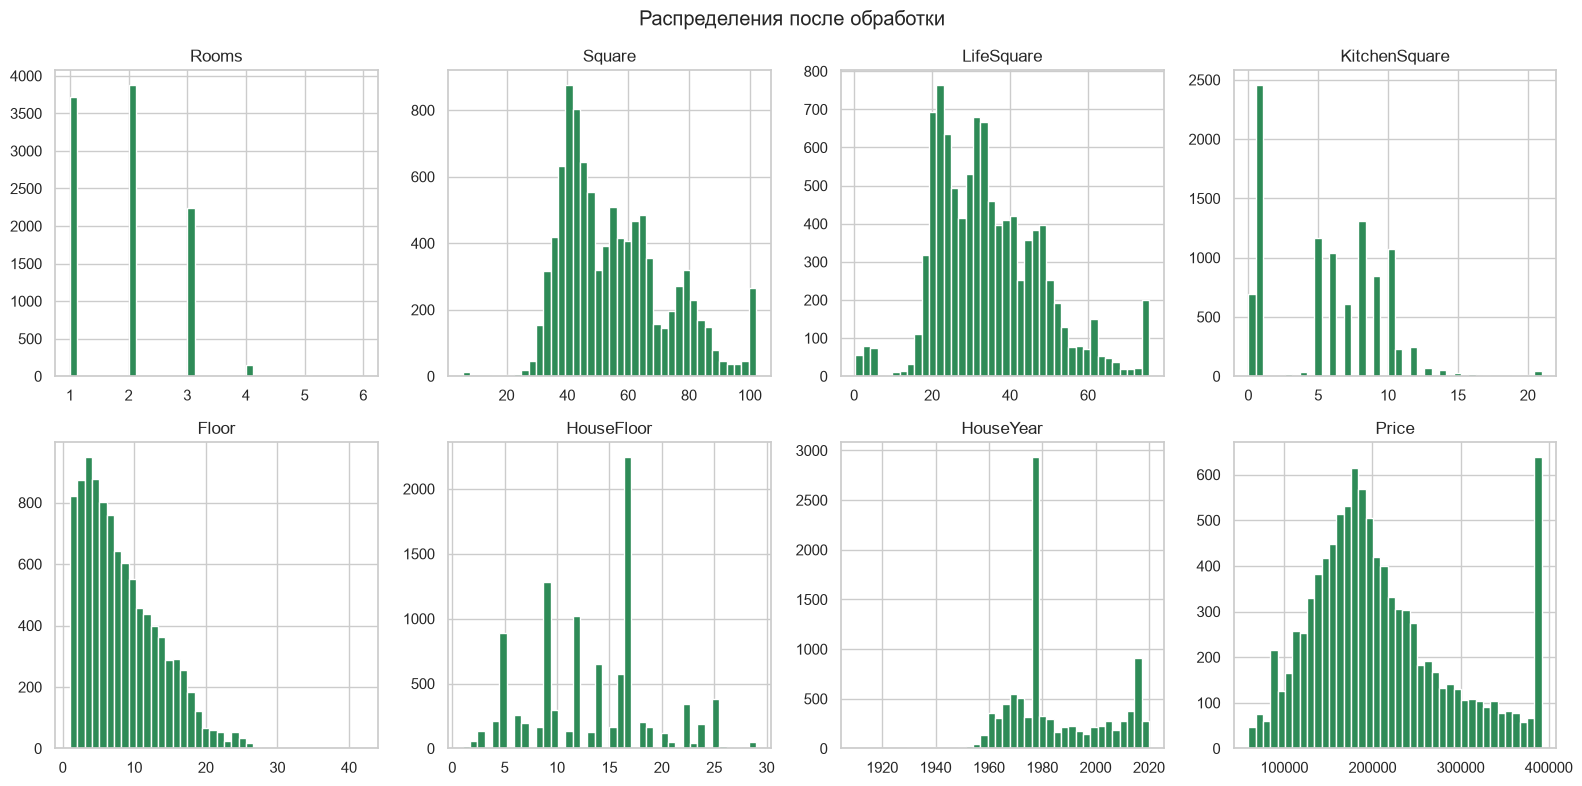

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.ravel(), suspect):
    ax.hist(df_clean[col].dropna(), bins=40, color="seagreen", edgecolor="white")
    ax.set_title(col)
plt.suptitle("Распределения после обработки")
plt.tight_layout()
plt.show()

Тепловая карта после обработки пустая — пропусков нет. BoxPlot и гистограммы стали компактнее: ушли год `20052011`, кухня `2014` и жилая площадь в тысячи квадратов. Оставшиеся «точки» на усах — уже правдоподобный разброс цен и площадей, а не явные ошибки.


## 3. Новые признаки и кодирование категорий

Создаём не меньше двух новых признаков и кодируем категории двумя способами из задания: **бинаризация** и **OHE**.


In [13]:
# индикатор исходного пропуска (приём из методички по очистке)
df_clean["LifeSquare_was_missing"] = df["LifeSquare"].isna().astype(int)

# новые числовые признаки
df_clean["HouseAge"] = 2020 - df_clean["HouseYear"]
df_clean["PricePerSqM"] = df_clean["Price"] / df_clean["Square"]
df_clean["KitchenShare"] = df_clean["KitchenSquare"] / df_clean["Square"]
df_clean["LifeSquareShare"] = df_clean["LifeSquare"] / df_clean["Square"]

df_clean[["HouseAge", "PricePerSqM", "KitchenShare", "LifeSquareShare", "LifeSquare_was_missing"]].head()

,HouseAge,PricePerSqM,KitchenShare,LifeSquareShare,LifeSquare_was_missing
0,6,2987.767031,0.097954,0.611749,1
1,54,4462.045990,0.200841,0.581666,0
2,32,3600.596698,0.127645,0.608509,0
3,43,4160.019670,0.024746,0.611749,1
4,48,5351.088794,0.140001,0.599867,0


Смысл новых колонок:
- `HouseAge` — возраст дома на 2020 год (последний год в выборке);
- `PricePerSqM` — цена квадратного метра;
- `KitchenShare` и `LifeSquareShare` — доли кухни и жилой площади;
- `LifeSquare_was_missing` — бинарный флаг: жилая площадь изначально была пустой.


In [14]:
print("Категории до кодирования:")
for col in ["Ecology_2", "Ecology_3", "Shops_2"]:
    print(col, df_clean[col].value_counts().to_dict())

# бинаризация признака (A/B -> 0/1)
df_clean["Shops_2"] = df_clean["Shops_2"].map({"A": 0, "B": 1})

# OHE-кодирование остальных категорий
df_clean = pd.get_dummies(df_clean, columns=["Ecology_2", "Ecology_3"], drop_first=True)

# Id не несёт информации для анализа
df_clean = df_clean.drop(columns=["Id"])

print()
print("Столбцы после кодирования:")
print(df_clean.columns.tolist())
df_clean[["Shops_2", "Ecology_2_B", "Ecology_3_B"]].head()

Категории до кодирования:
Ecology_2 {'B': 9903, 'A': 97}
Ecology_3 {'B': 9725, 'A': 275}
Shops_2 {'B': 9175, 'A': 825}

Столбцы после кодирования:
['DistrictId', 'Rooms', 'Square', 'LifeSquare', 'KitchenSquare', 'Floor', 'HouseFloor', 'HouseYear', 'Ecology_1', 'Social_1', 'Social_2', 'Social_3', 'Healthcare_1', 'Helthcare_2', 'Shops_1', 'Shops_2', 'Price', 'LifeSquare_was_missing', 'HouseAge', 'PricePerSqM', 'KitchenShare', 'LifeSquareShare', 'Ecology_2_B', 'Ecology_3_B']


,Shops_2,Ecology_2_B,Ecology_3_B
0,1,True,True
1,1,True,True
2,1,True,True
3,1,True,True
4,1,True,True


`Shops_2` стал 0/1. Для `Ecology_2` и `Ecology_3` появилось по одному дамми-столбцу (`*_B`): значение `A` кодируется нулями (вариант `drop_first=True`, чтобы не дублировать информацию).


## 4. Стандартизация и нормализация

Признаки в разных единицах: цена — сотни тысяч, площадь — десятки, экология — доли единицы. Без масштабирования модели, чувствительные к расстояниям и градиенту, «смотрят» только на большие числа.

- **нормализация (MinMax)** — сжимает значения в \([0; 1]\);
- **стандартизация (StandardScaler)** — среднее 0, стандартное отклонение 1.

По методичке нормализация удобнее для kNN, стандартизация — для линейных моделей. Деревьям масштаб не важен. Ниже применяем оба способа к числовым признакам (дамми и флаги уже в \([0; 1]\), их не трогаем).


In [15]:
binary_cols = ["Shops_2", "Ecology_2_B", "Ecology_3_B", "LifeSquare_was_missing"]
num_cols = [c for c in df_clean.columns if c not in binary_cols]

print("Масштабируем столбцы:")
print(num_cols)

df_std = df_clean.copy()
df_mm = df_clean.copy()

df_std[num_cols] = StandardScaler().fit_transform(df_clean[num_cols])
df_mm[num_cols] = MinMaxScaler().fit_transform(df_clean[num_cols])

print()
print("После стандартизации (ожидаем mean ≈ 0, std ≈ 1):")
display(df_std[num_cols].describe().T[["mean", "std", "min", "max"]].round(3))

print("После нормализации (ожидаем min = 0, max = 1):")
display(df_mm[num_cols].describe().T[["mean", "std", "min", "max"]].round(3))

Масштабируем столбцы:
['DistrictId', 'Rooms', 'Square', 'LifeSquare', 'KitchenSquare', 'Floor', 'HouseFloor', 'HouseYear', 'Ecology_1', 'Social_1', 'Social_2', 'Social_3', 'Healthcare_1', 'Helthcare_2', 'Shops_1', 'Price', 'HouseAge', 'PricePerSqM', 'KitchenShare', 'LifeSquareShare']

После стандартизации (ожидаем mean ≈ 0, std ≈ 1):


,mean,std,min,max
DistrictId,0.0,1.0,-1.156,3.639
Rooms,0.0,1.0,-1.093,5.061
Square,-0.0,1.0,-2.872,2.655
LifeSquare,0.0,1.0,-2.472,2.954
KitchenSquare,0.0,1.0,-1.434,3.810
Floor,0.0,1.0,-1.436,6.387
HouseFloor,-0.0,1.0,-2.139,2.696
HouseYear,-0.0,1.0,-4.066,1.908
Ecology_1,-0.0,1.0,-0.999,3.386
Social_1,-0.0,1.0,-1.408,2.813


После нормализации (ожидаем min = 0, max = 1):


,mean,std,min,max
DistrictId,0.241,0.209,0.0,1.0
Rooms,0.178,0.162,0.0,1.0
Square,0.520,0.181,0.0,1.0
LifeSquare,0.456,0.184,0.0,1.0
KitchenSquare,0.273,0.191,0.0,1.0
Floor,0.184,0.128,0.0,1.0
HouseFloor,0.442,0.207,0.0,1.0
HouseYear,0.681,0.167,0.0,1.0
Ecology_1,0.228,0.228,0.0,1.0
Social_1,0.334,0.237,0.0,1.0


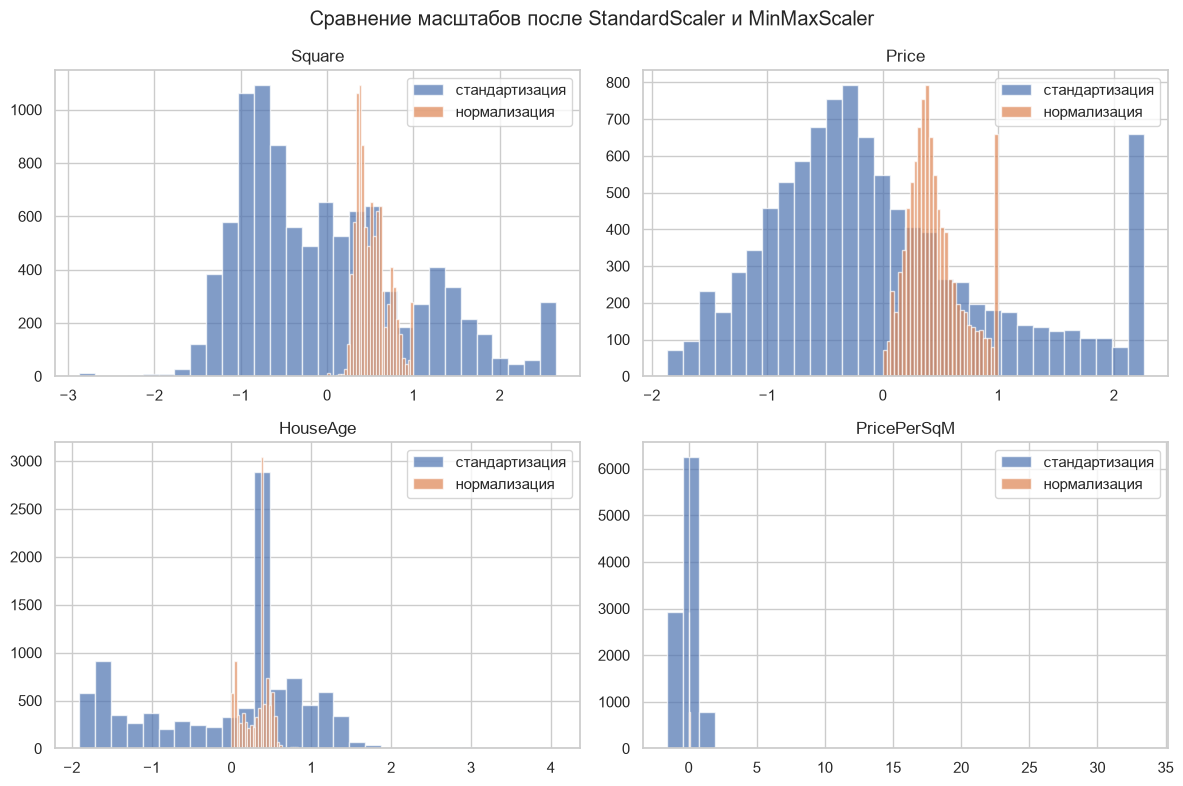

In [16]:
compare_cols = ["Square", "Price", "HouseAge", "PricePerSqM"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), compare_cols):
    ax.hist(df_std[col], bins=30, alpha=0.7, label="стандартизация")
    ax.hist(df_mm[col], bins=30, alpha=0.7, label="нормализация")
    ax.set_title(col)
    ax.legend()
plt.suptitle("Сравнение масштабов после StandardScaler и MinMaxScaler")
plt.tight_layout()
plt.show()

## Итог

| Этап | Что сделано |
|------|-------------|
| Импорт | Загружен `train.csv` (10 000 квартир), просмотрены типы и статистики |
| Пропуски | Найдены в `LifeSquare` (21%) и `Healthcare_1` (48%), заполнены; тепловая карта после очистки пустая |
| Выбросы | Исправлены годы, комнаты и этажность; хвосты обрезаны по IQR; BoxPlot «до / после» это подтверждают |
| Новые признаки | `HouseAge`, `PricePerSqM`, доли площадей, флаг пропуска `LifeSquare` |
| Кодирование | Бинаризация `Shops_2`, OHE для `Ecology_2` и `Ecology_3` |
| Масштаб | Показаны и стандартизация, и нормализация |

Для дальнейшей работы с моделями обычно оставляют **одну** из двух масштабированных таблиц: `df_std` или `df_mm`.


In [17]:
print("Итоговая таблица (после очистки и кодирования, до масштабирования):", df_clean.shape)
print("Стандартизированная:", df_std.shape)
print("Нормализованная:", df_mm.shape)
df_clean.head()

Итоговая таблица (после очистки и кодирования, до масштабирования): (10000, 24)
Стандартизированная: (10000, 24)
Нормализованная: (10000, 24)


,DistrictId,Rooms,Square,LifeSquare,KitchenSquare,Floor,HouseFloor,HouseYear,Ecology_1,Social_1,Social_2,Social_3,Healthcare_1,Helthcare_2,Shops_1,Shops_2,Price,LifeSquare_was_missing,HouseAge,PricePerSqM,KitchenShare,LifeSquareShare,Ecology_2_B,Ecology_3_B
0,27,3.0,102.089242,62.452976,10.0,4,10.0,2014,0.075424,11,3097,0,900.0,0,0,1,305018.871089,1,6,2987.767031,0.097954,0.611749,True,True
1,22,1.0,39.832524,23.169223,8.0,7,8.0,1966,0.118537,30,6207,1,1183.0,1,0,1,177734.553407,0,54,4462.045990,0.200841,0.581666,True,True
2,1,3.0,78.342215,47.671972,10.0,2,17.0,1988,0.025609,33,5261,0,240.0,3,1,1,282078.720850,0,32,3600.596698,0.127645,0.608509,True,True
3,1,1.0,40.409907,24.720714,1.0,10,22.0,1977,0.007122,1,264,0,900.0,0,1,1,168106.007630,1,43,4160.019670,0.024746,0.611749,True,True
4,94,2.0,64.285067,38.562517,9.0,16,16.0,1972,0.282798,33,8667,2,900.0,0,6,1,343995.102962,0,48,5351.088794,0.140001,0.599867,True,True
